**ONE BRANCH 3D CNN APPROACH**

Health data is strucutured as the results from a linear regression model in which the CVS file is three columns:

[date | visits | baseline_visits]

This strucuture limits vulnerability factors, in theory the strucuture can still have aggregated data strucuture such as

[date | Patient visit details | Patient Demographics]

The one-branch CNN would learn how weather relates to each group's health outcome, but it would not directly learn how changing demographic or vulnerability characteristics influence risk, because those characteristics are not input features.
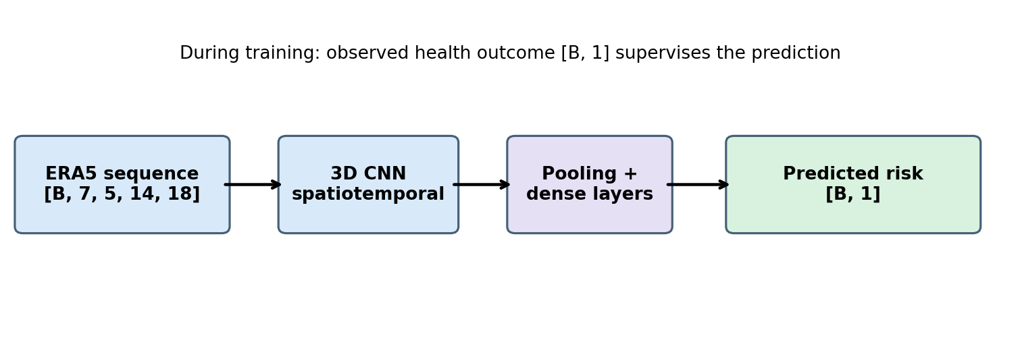 

vs

**TWO BRANCH 3D CNN APPROACH**

The health data goes through its own ML model
 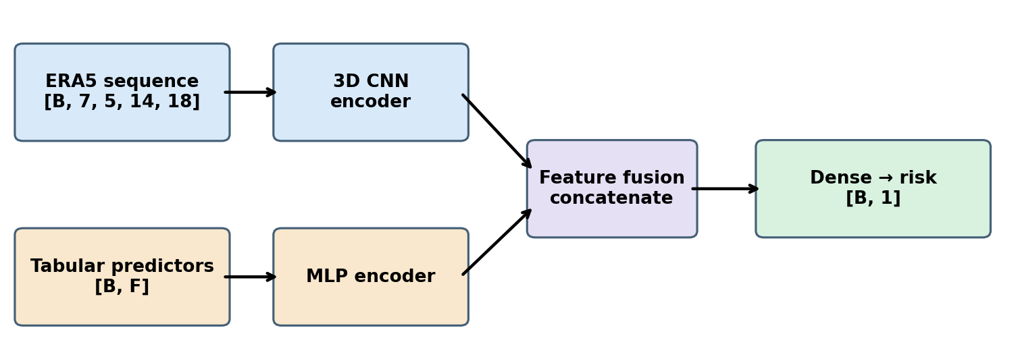

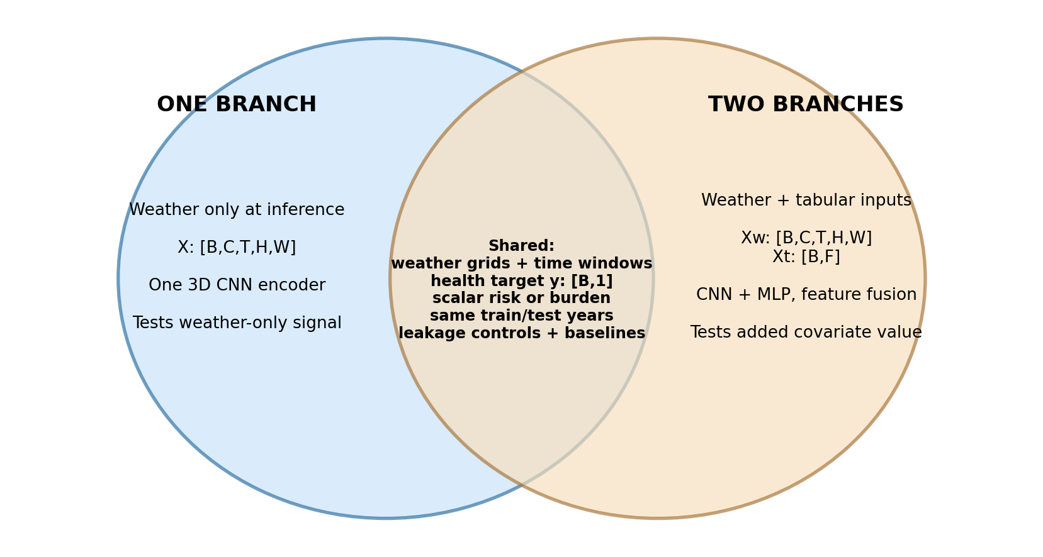

Notation: B = batch size; C = weather variables/channels; T = days in the sequence; H/W = grid dimensions; F = tabular features. Both example outputs are one continuous number per sample. A multi-location or multi-outcome target would require an explicitly revised output shape.

**THE DATA STRUCUTURE FOR ONE BRANCH APPROACH EXAMPLE**

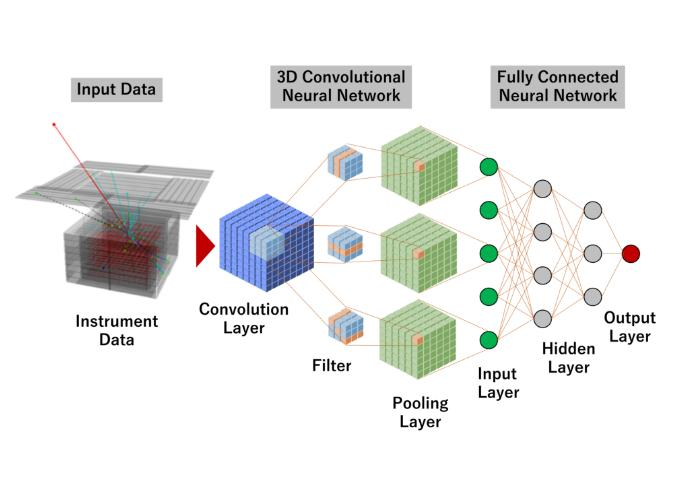

In [3]:
"""Weather-only CNN for next-day excess visit percentage.

Required files:
  daily_weather.nc: gph (hPa), (valid_time, latitude, longitude).
  daily_health.csv: date,visits,baseline_visits; one row/day for one study area.

Weather must already be DAILY and use the same day convention as health records.
This script deliberately does not infer daily aggregation or fit a baseline.
Baseline values must come from a model fitted ONLY on the training period.
Target is a percentage increase, NOT a probability or a causal heat effect.
Run: python one_branch_cnn.py
Dependencies: numpy pandas xarray netCDF4 torch
"""
from pathlib import Path
import copy
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

In [4]:
# EDIT THESE PATHS AND DATES for your files and health-data coverage.
WEATHER_FILE = Path(r"D:\ERA 5 Data\ERA5_Camden\daily_weather.nc")
HEALTH_FILE = Path(r"D:\ERA 5 Data\ERA5_Camden\daily_health_sample.csv")
OUTPUT_DIR = Path("cnn_results")
TIME_DIM = "valid_time"
TRAIN_END = pd.Timestamp("2018-12-31")
VAL_END = pd.Timestamp("2021-12-31")
LEAD_DAYS = 1  # today's complete daily weather -> tomorrow's health burden
BATCH_SIZE = 32
EPOCHS = 50
SEED = 20

In [5]:
class WeatherCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1),  # unrestricted numerical output, not sigmoid
        )

    def forward(self, x):
        return self.network(x)

In [ ]:
def load_weather(path):
    with xr.open_dataset(path, chunks=None) as ds:
        expected = {TIME_DIM, "latitude", "longitude"}
        if "gph" not in ds or set(ds["gph"].dims) != expected:
            raise ValueError(
                "gph must have valid_time, latitude, longitude dimensions."
            )

        stamps = pd.DatetimeIndex(ds[TIME_DIM].values)
        if stamps.tz is not None or not stamps.equals(stamps.normalize()):
            raise ValueError("Use timezone-naive daily date labels at midnight.")
        if stamps.has_duplicates or stamps.hasnans:
            raise ValueError("Weather needs one valid row per date.")

        ds = ds.sortby(TIME_DIM)
        dates = pd.DatetimeIndex(ds[TIME_DIM].values)

        gph_da = ds["gph"].transpose(
            TIME_DIM, "latitude", "longitude"
        )

        # This loads the full array into memory.
        gph = gph_da.values
        x = gph[:, None, :, :].astype(np.float32, copy=False)

        lat = ds.latitude.values.copy()
        lon = ds.longitude.values.copy()

    if not np.isfinite(x).all():
        raise ValueError(
            "Weather contains missing/infinite values; resolve before training."
        )

    return x, dates, lat, lon

In [7]:
with xr.open_dataset(WEATHER_FILE) as ds:
    gph_da = ds["gph"].transpose(TIME_DIM, "latitude", "longitude")
    print("Shape:", gph_da.shape)
    print("Approx. float32 size (GiB):", gph_da.size * 4 / 1024**3)

Shape: (3366, 97, 161)
Approx. float32 size (GiB): 0.1958266720175743


In [8]:
def prepare_pairs():
    x, dates, lat, lon = load_weather(WEATHER_FILE)
    health = pd.read_csv(HEALTH_FILE)
    required = {"date", "visits", "baseline_visits"}
    if not required.issubset(health.columns):
        raise ValueError(f"Health CSV must include {required}")
    health["date"] = pd.to_datetime(health["date"], format="%Y-%m-%d", errors="raise")
    if health.date.isna().any() or health.date.duplicated().any():
        raise ValueError("Health CSV needs one valid row per date for one area.")
    for col in ("visits", "baseline_visits"):
        health[col] = pd.to_numeric(health[col], errors="raise")
    if not np.isfinite(health[["visits", "baseline_visits"]].to_numpy()).all():
        raise ValueError("Health counts/baselines contain missing or infinite values.")
    if (health.visits < 0).any() or (health.baseline_visits <= 0).any():
        raise ValueError("Visits must be nonnegative; baseline visits must be positive.")
    health["target_pct"] = 100 * (health.visits - health.baseline_visits) / health.baseline_visits
    pairs = pd.DataFrame({"weather_index": np.arange(len(dates)), "weather_date": dates})
    # Calendar offset, NOT next row: avoids joining September to the following May.
    pairs["target_date"] = pairs.weather_date + pd.Timedelta(days=LEAD_DAYS)
    pairs = pairs.merge(health.rename(columns={"date": "target_date"}),
                        on="target_date", how="inner", validate="one_to_one")
    pairs = pairs.sort_values("target_date").reset_index(drop=True)
    print(f"Matched {len(pairs)} of {len(dates)} weather dates to health targets.")
    if pairs.empty:
        raise ValueError("No matching weather/health dates.")
    x = x[pairs.weather_index.to_numpy()]
    y = pairs.target_pct.to_numpy(dtype=np.float32).reshape(-1, 1)
    return x, y, pairs, lat, lon

In [9]:

def main():
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    x, y, pairs, lat, lon = prepare_pairs()

    # 1. Split chronologically
    train = (pairs.target_date <= TRAIN_END).to_numpy()

    val = (
        (pairs.target_date > TRAIN_END)
        & (pairs.target_date <= VAL_END)
    ).to_numpy()

    test = (pairs.target_date > VAL_END).to_numpy()

    if not all(mask.sum() for mask in (train, val, test)):
        raise ValueError(
            "Train, validation, and test need data; edit split dates."
        )

    # 2. Normalize using training data only
    mean = x[train].mean(axis=(0, 2, 3), keepdims=True)
    std = x[train].std(axis=(0, 2, 3), keepdims=True)
    std = np.where(std > 0, std, 1).astype(np.float32)

    x = ((x - mean) / std).astype(np.float32)

    loader = DataLoader(
        TensorDataset(
            torch.from_numpy(x[train]),
            torch.from_numpy(y[train])
        ),
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    # Use batches for validation and testing too
    val_loader = DataLoader(
        TensorDataset(
            torch.from_numpy(x[val]),
            torch.from_numpy(y[val])
        ),
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_loader = DataLoader(
        TensorDataset(torch.from_numpy(x[test])),
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # 3. Set up the model
    model = WeatherCNN().to(device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )
    loss_fn = nn.MSELoss()

    best_loss = float("inf")
    best_weights = None

    train_losses = []
    val_losses = []

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    print("X:", x.shape, "y:", y.shape, "Device:", device)
    print("Split sizes:", train.sum(), val.sum(), test.sum())

    # 4. Train
    for epoch in range(EPOCHS):
        model.train()
        train_total = 0.0

        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            prediction = model(xb)
            loss = loss_fn(prediction, yb)

            loss.backward()
            optimizer.step()

            train_total += loss.item() * len(xb)

        train_loss = train_total / train.sum()

        # Validate after each epoch
        model.eval()
        val_total = 0.0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                yb = yb.to(device)

                val_prediction = model(xb)
                batch_loss = loss_fn(val_prediction, yb)

                val_total += batch_loss.item() * len(xb)

        val_loss = val_total / val.sum()

        # INSIDE the loop: record one value per epoch
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        # Keep weights with the lowest validation error
        if val_loss < best_loss:
            best_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())

        if epoch == 0 or (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch + 1}: "
                f"train MSE={train_loss:.2f}; "
                f"val MSE={val_loss:.2f}"
            )

    # 5. AFTER the loop: save learning history
    epochs = np.arange(1, len(train_losses) + 1)

    history = pd.DataFrame({
        "epoch": epochs,
        "train_mse": train_losses,
        "val_mse": val_losses
    })

    history.to_csv(
        OUTPUT_DIR / "learning_history.csv",
        index=False
    )

    # 6. Restore the best weights and predict test outcomes
    model.load_state_dict(best_weights)
    model.eval()

    prediction_batches = []

    with torch.no_grad():
        for (xb,) in test_loader:
            prediction = model(xb.to(device))
            prediction_batches.append(
                prediction.cpu().numpy().ravel()
            )

    predicted = np.concatenate(prediction_batches)
    observed = y[test].ravel()

    # 7. Evaluate test predictions
    mae = np.mean(np.abs(predicted - observed))
    rmse = np.sqrt(np.mean((predicted - observed) ** 2))

    reference = np.full_like(observed, y[train].mean())
    reference_mae = np.mean(np.abs(reference - observed))

    print(
        f"Test MAE: {mae:.2f} percentage points; "
        f"RMSE: {rmse:.2f}"
    )
    print(
        f"Training-mean comparator MAE: {reference_mae:.2f}"
    )

    # 8. Save test predictions
    results = pairs.loc[
        test,
        ["weather_date", "target_date", "visits", "baseline_visits"]
    ].copy()

    results["observed_excess_pct"] = observed
    results["predicted_excess_pct"] = predicted

    results.to_csv(
        OUTPUT_DIR / "test_predictions.csv",
        index=False
    )

    # 9. Save model and preprocessing information
    torch.save(
        model.state_dict(),
        OUTPUT_DIR / "weather_cnn_weights.pt"
    )

    np.savez(
        OUTPUT_DIR / "weather_preprocessing.npz",
        mean=mean,
        std=std,
        latitude=lat,
        longitude=lon,
        channel_order=np.array(["gph"]),
        lead_days=np.array(LEAD_DAYS)
    )

In [10]:
def predict_new_weather(netcdf_path, results_dir=OUTPUT_DIR):
    """Call after training. Requires WEATHER ONLY, same units/grid/day definition.

    Example in a notebook:
      from one_branch_cnn import predict_new_weather
      predictions = predict_new_weather('new_daily_weather.nc')
    Returns percentages; no observed future health visits are needed.
    """
    results_dir = Path(results_dir)
    x, dates, lat, lon = load_weather(netcdf_path)
    with np.load(results_dir / "weather_preprocessing.npz") as prep:
        if not np.array_equal(lat, prep["latitude"]) or not np.array_equal(lon, prep["longitude"]):
            raise ValueError("New weather must use the same coordinates and ordering.")
        x = ((x - prep["mean"]) / prep["std"]).astype(np.float32)
        lead = int(prep["lead_days"])
    model = WeatherCNN()
    model.load_state_dict(torch.load(results_dir / "weather_cnn_weights.pt",
                                    map_location="cpu", weights_only=True))
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(x), BATCH_SIZE):
            outputs.append(model(torch.from_numpy(x[start:start+BATCH_SIZE])).numpy().ravel())
    return pd.DataFrame({"weather_date": dates,
                         "target_date": dates + pd.Timedelta(days=lead),
                         "predicted_excess_pct": np.concatenate(outputs)})


In [11]:
if __name__ == "__main__":
    main()

Shape: (3366, 97, 161)
Approx. float32 size (GiB): 0.1958266720175743
Matched 3213 of 3366 weather dates to health targets.
X: (3213, 1, 97, 161) y: (3213, 1) Device: cpu
Split sizes: 2295 459 459
Epoch 1: train MSE=194.51; val MSE=191.56
Epoch 10: train MSE=187.21; val MSE=190.14
Epoch 20: train MSE=186.86; val MSE=191.49
Epoch 30: train MSE=186.51; val MSE=191.12
Epoch 40: train MSE=186.66; val MSE=190.05
Epoch 50: train MSE=186.24; val MSE=191.55
Test MAE: 10.75 percentage points; RMSE: 13.54
Training-mean comparator MAE: 10.72


In [12]:
#Load the results for analysis
results = pd.read_csv(
    Path("cnn_results") / "test_predictions.csv",
    parse_dates=["weather_date", "target_date"]
)

print(results.head())

  weather_date target_date  visits  baseline_visits  observed_excess_pct  \
0   2022-05-01  2022-05-02      99           97.867             1.157694   
1   2022-05-02  2022-05-03     120           97.735            22.780989   
2   2022-05-03  2022-05-04     101           97.603             3.480426   
3   2022-05-04  2022-05-05      96           97.472            -1.510177   
4   2022-05-05  2022-05-06     115           97.342            18.140165   

   predicted_excess_pct  
0              4.843794  
1              4.973360  
2              4.993253  
3              4.948559  
4              4.799687  


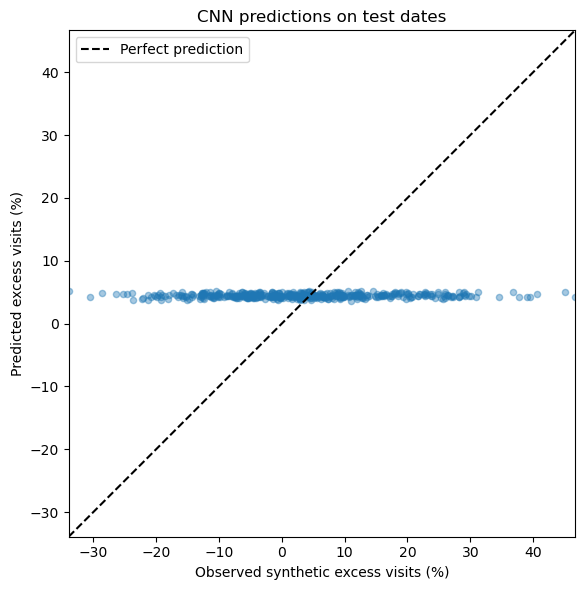

In [13]:
#Load the observed and predicted values to plot
observed = results["observed_excess_pct"].to_numpy()
predicted = results["predicted_excess_pct"].to_numpy()

limits = [
    min(observed.min(), predicted.min()),
    max(observed.max(), predicted.max())
]

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(observed, predicted, alpha=0.4, s=20)
ax.plot(limits, limits, "k--", label="Perfect prediction")

ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("Observed synthetic excess visits (%)")
ax.set_ylabel("Predicted excess visits (%)")
ax.set_title("CNN predictions on test dates")
ax.legend()

plt.tight_layout()
plt.show()

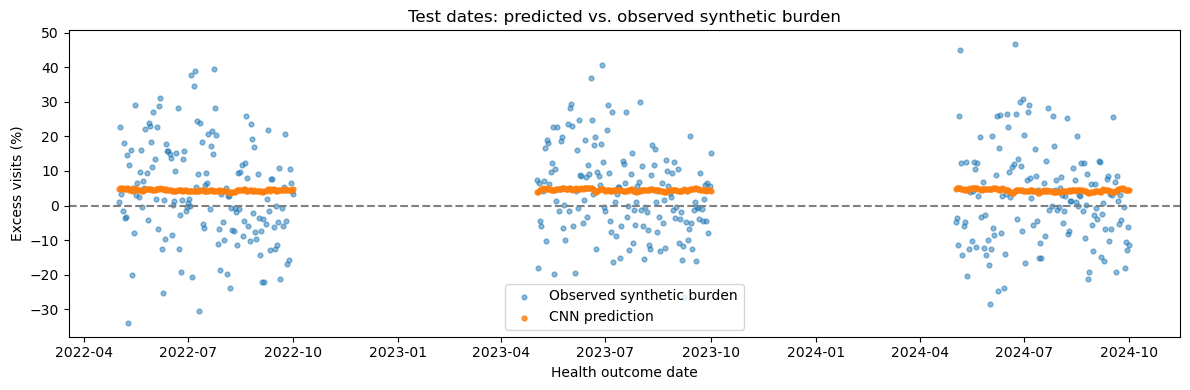

In [14]:
# Plot the observed and predicted values over time
plt.figure(figsize=(12, 4))

plt.scatter(
    results["target_date"],
    results["observed_excess_pct"],
    s=12, alpha=0.5, label="Observed synthetic burden"
)
plt.scatter(
    results["target_date"],
    results["predicted_excess_pct"],
    s=12, alpha=0.8, label="CNN prediction"
)

plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("Health outcome date")
plt.ylabel("Excess visits (%)")
plt.title("Test dates: predicted vs. observed synthetic burden")
plt.legend()
plt.tight_layout()
plt.show()

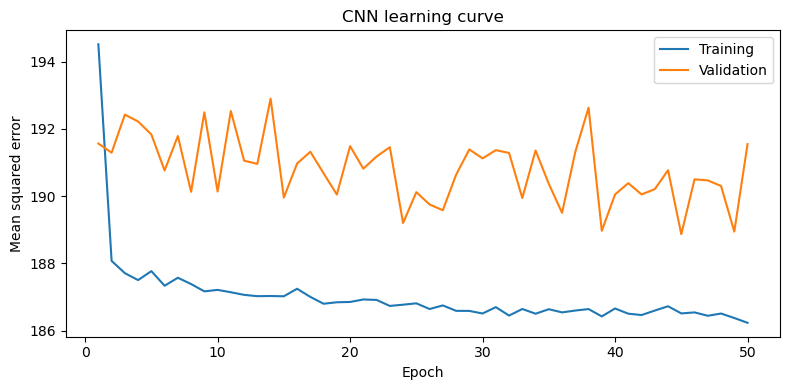

In [15]:

history_file = Path("cnn_results") / "learning_history.csv"
if not history_file.is_file():
    raise FileNotFoundError(f"Learning-history CSV not found: {history_file}")

history = pd.read_csv(history_file)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history["epoch"], history["train_mse"], label="Training")
ax.plot(history["epoch"], history["val_mse"], label="Validation")
ax.set(xlabel="Epoch", ylabel="Mean squared error", title="CNN learning curve")
ax.legend()
fig.tight_layout()
plt.show()